In [2]:
import pandas as pd

In [3]:
df = pd.read_csv('../data/raw/cleaned_data_v2.csv')

In [4]:
df.head()

,bhk,type,locality,area,price,price_unit,region,status,age,final_price
0,3,Apartment,Lak And Hanware The Residency Tower,685,2.50,Cr,Andheri West,Ready to move,New,250.00
1,2,Apartment,Radheya Sai Enclave Building No 2,640,52.51,L,Naigaon East,Under Construction,New,52.51
2,2,Apartment,Romell Serene,610,1.73,Cr,Borivali West,Under Construction,New,173.00
3,2,Apartment,Soundlines Codename Urban Rainforest,876,59.98,L,Panvel,Under Construction,New,59.98
4,2,Apartment,Origin Oriana,659,94.11,L,Mira Road East,Under Construction,New,94.11


In [5]:
df.shape

(76038, 10)

In [6]:
df.columns.tolist()

['bhk',
 'type',
 'locality',
 'area',
 'price',
 'price_unit',
 'region',
 'status',
 'age',
 'final_price']

In [7]:
df[["price", "price_unit", "final_price"]].head(10)

,price,price_unit,final_price
0,2.50,Cr,250.00
1,52.51,L,52.51
2,1.73,Cr,173.00
3,59.98,L,59.98
4,94.11,L,94.11
5,3.30,Cr,330.00
6,1.99,Cr,199.00
7,2.89,Cr,289.00
8,29.84,L,29.84
9,2.72,Cr,272.00


In [8]:
print(df["price_unit"].value_counts(dropna=False))
print("\nMissing values:")
print(df[["price", "price_unit", "final_price"]].isnull().sum())

price_unit
Cr    40981
L     35057
Name: count, dtype: int64

Missing values:
price          0
price_unit     0
final_price    0
dtype: int64


In [9]:
# Check whether final_price matches price converted to lakhs
expected_price = df["price"].where(
    df["price_unit"].eq("L"),
    df["price"] * 100
)

difference = (df["final_price"] - expected_price).abs()

print("Maximum conversion difference:", difference.max())
print("Rows with inconsistent prices:", (difference > 0.01).sum())
print("\nFinal price summary (lakhs):")
print(df["final_price"].describe().round(2))

Maximum conversion difference: 4.547473508864641e-13
Rows with inconsistent prices: 0

Final price summary (lakhs):
count    76038.00
mean       168.42
std        217.67
min          4.49
25%         64.00
50%        110.00
75%        194.00
max       6000.00
Name: final_price, dtype: float64


In [10]:
df.dtypes

bhk              int64
type            object
locality        object
area             int64
price          float64
price_unit      object
region          object
status          object
age             object
final_price    float64
dtype: object

In [11]:
df.isnull().sum()

bhk            0
type           0
locality       0
area           0
price          0
price_unit     0
region         0
status         0
age            0
final_price    0
dtype: int64

In [12]:
df.duplicated().sum()

np.int64(20312)

In [13]:
print("\nUNIQUE VALUES IN CATEGORICAL COLUMNS")
for col in ["type", "region", "status", "age"]:
    print(f"\n{col}:")
    print(df[col].value_counts().head(10))


UNIQUE VALUES IN CATEGORICAL COLUMNS

type:
type
Apartment            74854
Studio Apartment       882
Villa                  226
Independent House       73
Penthouse                3
Name: count, dtype: int64

region:
region
Thane West        14868
Mira Road East     9902
Dombivali          3041
Kandivali East     2568
Kharghar           2362
Andheri West       1842
Kalyan West        1815
Virar              1557
Mulund West        1526
Panvel             1474
Name: count, dtype: int64

status:
status
Ready to move         44982
Under Construction    31056
Name: count, dtype: int64

age:
age
New        38072
Resale     23357
Unknown    14609
Name: count, dtype: int64


In [14]:
# Features (X): information used to predict price
feature_columns = [
    "bhk",
    "type",
    "locality",
    "area",
    "region",
    "status",
    "age"
]

X = df[feature_columns]
y = df["final_price"]

In [15]:
X.shape

(76038, 7)

In [16]:
y.shape

(76038,)

In [17]:
X.head()

,bhk,type,locality,area,region,status,age
0,3,Apartment,Lak And Hanware The Residency Tower,685,Andheri West,Ready to move,New
1,2,Apartment,Radheya Sai Enclave Building No 2,640,Naigaon East,Under Construction,New
2,2,Apartment,Romell Serene,610,Borivali West,Under Construction,New
3,2,Apartment,Soundlines Codename Urban Rainforest,876,Panvel,Under Construction,New
4,2,Apartment,Origin Oriana,659,Mira Road East,Under Construction,New


In [18]:
y.head()

0    250.00
1     52.51
2    173.00
3     59.98
4     94.11
Name: final_price, dtype: float64

In [19]:
from sklearn.model_selection import train_test_split

In [20]:
X_train, X_test, y_train, y_test = train_test_split (
    X,
    y,
    test_size = 0.2,
    random_state = 42
)

In [21]:
X_train.shape, y_train.shape

((60830, 7), (60830,))

In [22]:
X_test.shape, y_test.shape

((15208, 7), (15208,))

In [23]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.impute import SimpleImputer

categorical_features = [
    "type", "locality", "region", "status", "age"
]

numeric_features = ["bhk", "area"]

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", SimpleImputer(strategy="median"), numeric_features),
        ("categorical", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore"))
        ]), categorical_features)
    ]
)

model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

model.fit(X_train, y_train)

print("Model training complete!")

Model training complete!


In [24]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

y_pred = model.predict(X_test)

In [25]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

In [26]:
print(f"MAE: ₹{mae:.2f} lakhs") 
print(f"MSE: ₹{mse:.2f} lakhs") 
print(f"RMSE: ₹{rmse:.2f} lakhs") 

MAE: ₹35.13 lakhs
MSE: ₹6351.50 lakhs
RMSE: ₹79.70 lakhs


In [27]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error

baseline = DummyRegressor(strategy="median")
baseline.fit(X_train, y_train)

baseline_predictions = baseline.predict(X_test)

baseline_mae = mean_absolute_error(
    y_test, baseline_predictions
)

print(f"Baseline MAE: ₹{baseline_mae:.2f} lakhs")
print(f"Linear Regression MAE: ₹{mae:.2f} lakhs")

Baseline MAE: ₹103.54 lakhs
Linear Regression MAE: ₹35.13 lakhs


In [28]:
# Create a table of actual and predicted prices
results = pd.DataFrame({
    "actual_price": y_test.reset_index(drop=True),
    "predicted_price": y_pred
})

# Calculate the signed prediction error
results["residual"] = (
    results["actual_price"] - results["predicted_price"]
)

# Calculate the size of the error, regardless of direction
results["absolute_error"] = results["residual"].abs()

# Display the 10 predictions with the largest errors
display(
    results.nlargest(10, "absolute_error")
)

,actual_price,predicted_price,residual,absolute_error
10291,5000.0,2106.142614,2893.857386,2893.857386
12306,5555.0,2731.787796,2823.212204,2823.212204
15108,3400.0,1600.264107,1799.735893,1799.735893
13691,3400.0,1762.427424,1637.572576,1637.572576
3694,3300.0,1748.657411,1551.342589,1551.342589
10855,5000.0,3586.557256,1413.442744,1413.442744
6527,2500.0,1335.410920,1164.589080,1164.589080
8895,2500.0,3639.000092,-1139.000092,1139.000092
7439,925.0,1992.427359,-1067.427359,1067.427359
7846,925.0,1992.427359,-1067.427359,1067.427359


In [29]:
# Get the original features for the 10 worst predictions
worst_indices = results.nlargest(10, "absolute_error").index

worst_properties = X_test.reset_index(drop=True).iloc[worst_indices].copy()

# Add actual and predicted prices to the feature table
worst_properties["actual_price"] = y_test.reset_index(drop=True).iloc[worst_indices].values
worst_properties["predicted_price"] = y_pred[worst_indices]

display(worst_properties)

,bhk,type,locality,area,region,status,age,actual_price,predicted_price
10291,8,Apartment,Rustomjee Elements,7500,Andheri West,Ready to move,New,5000.0,2106.142614
12306,3,Apartment,Rustomjee Paramount Wing F,10893,Santacruz West,Under Construction,New,5555.0,2731.787796
15108,5,Apartment,Lodha The World Towers World One Tier III And ...,6000,Lower Parel,Ready to move,New,3400.0,1600.264107
13691,9,Apartment,Reputed Builder Varsha Apartments,6350,Juhu,Ready to move,Resale,3400.0,1762.427424
3694,10,Apartment,Reputed Builder Varsha Apartments,6200,Juhu,Ready to move,Resale,3300.0,1748.657411
10855,5,Apartment,Provenance Four Seasons Private Residences,7000,Worli,Under Construction,New,5000.0,3586.557256
6527,8,Apartment,Reputed Builder Atlantis,7800,Kharghar,Ready to move,Resale,2500.0,1335.410920
8895,6,Apartment,SD The Imperial Edge,10000,Tardeo,Ready to move,Unknown,2500.0,3639.000092
7439,3,Apartment,Lodha World One,3000,Lower Parel,Ready to move,Resale,925.0,1992.427359
7846,3,Apartment,Lodha World One,3000,Lower Parel,Ready to move,Resale,925.0,1992.427359


In [30]:
# Count how often each feature combination appears
feature_columns = [
    "bhk", "type", "locality", "area", "region", "status", "age"
]

duplicate_features = df.duplicated(
    subset=feature_columns,
    keep=False
)

# Show rows that share the same feature combination
duplicate_rows = df.loc[duplicate_features].sort_values(
    by=feature_columns
)

print("Rows involved in duplicate feature combinations:",
      len(duplicate_rows))

display(duplicate_rows.head(20))

Rows involved in duplicate feature combinations: 41336


,bhk,type,locality,area,price,price_unit,region,status,age,final_price
13935,1,Apartment,Asha Nagar,650,1.05,Cr,Mulund West,Ready to move,Resale,105.0
56072,1,Apartment,Asha Nagar,650,1.00,Cr,Mulund West,Ready to move,Resale,100.0
33348,1,Apartment,Dwarkesh Dham C H S,600,90.00,L,Dahisar West,Ready to move,Resale,90.0
33548,1,Apartment,Dwarkesh Dham C H S,600,90.00,L,Dahisar West,Ready to move,Resale,90.0
33627,1,Apartment,Dwarkesh Dham C H S,600,90.00,L,Dahisar West,Ready to move,Resale,90.0
34154,1,Apartment,Dwarkesh Dham C H S,600,90.00,L,Dahisar West,Ready to move,Resale,90.0
52360,1,Apartment,J B Heights,685,42.00,L,Karanjade,Ready to move,Resale,42.0
67016,1,Apartment,J B Heights,685,38.00,L,Karanjade,Ready to move,Resale,38.0
4894,1,Apartment,Radhe Krishna Heights,450,21.00,L,Karjat,Ready to move,New,21.0
5189,1,Apartment,Radhe Krishna Heights,450,22.90,L,Karjat,Ready to move,New,22.9


In [32]:
# Check exact duplicate rows across all columns
exact_duplicate_count = df.duplicated().sum()

print("Exact duplicate rows:", exact_duplicate_count)

# Check how many unique feature combinations exist
unique_feature_combinations = df[feature_columns].drop_duplicates().shape[0]

print("Unique feature combinations:", unique_feature_combinations)
print("Total dataset rows:", len(df))

Exact duplicate rows: 20312
Unique feature combinations: 46305
Total dataset rows: 76038


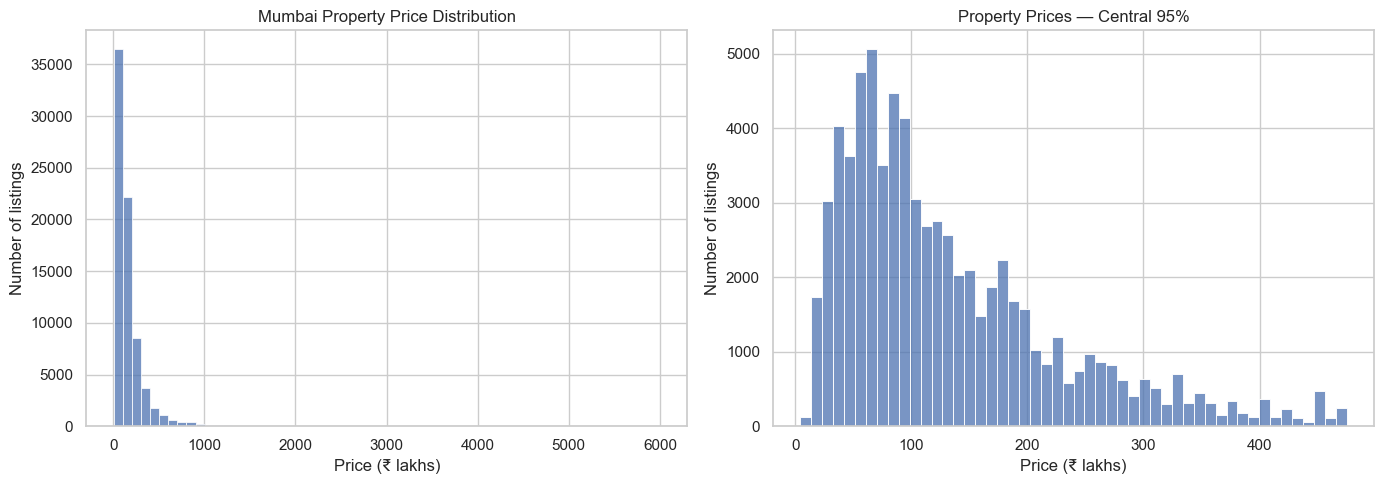

In [33]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Full price distribution
sns.histplot(
    data=df,
    x="final_price",
    bins=60,
    ax=axes[0]
)
axes[0].set_title("Mumbai Property Price Distribution")
axes[0].set_xlabel("Price (₹ lakhs)")
axes[0].set_ylabel("Number of listings")

# Distribution excluding the top 5% for visualization only
price_limit = df["final_price"].quantile(0.95)

sns.histplot(
    data=df[df["final_price"] <= price_limit],
    x="final_price",
    bins=50,
    ax=axes[1]
)
axes[1].set_title("Property Prices — Central 95%")
axes[1].set_xlabel("Price (₹ lakhs)")
axes[1].set_ylabel("Number of listings")

plt.tight_layout()
plt.show()

In [34]:
# Count rows after keeping one copy of each exact record
df_unique = df.drop_duplicates().copy()

print("Original rows:", len(df))
print("Rows after removing exact duplicates:", len(df_unique))
print("Rows removed:", len(df) - len(df_unique))

Original rows: 76038
Rows after removing exact duplicates: 55726
Rows removed: 20312


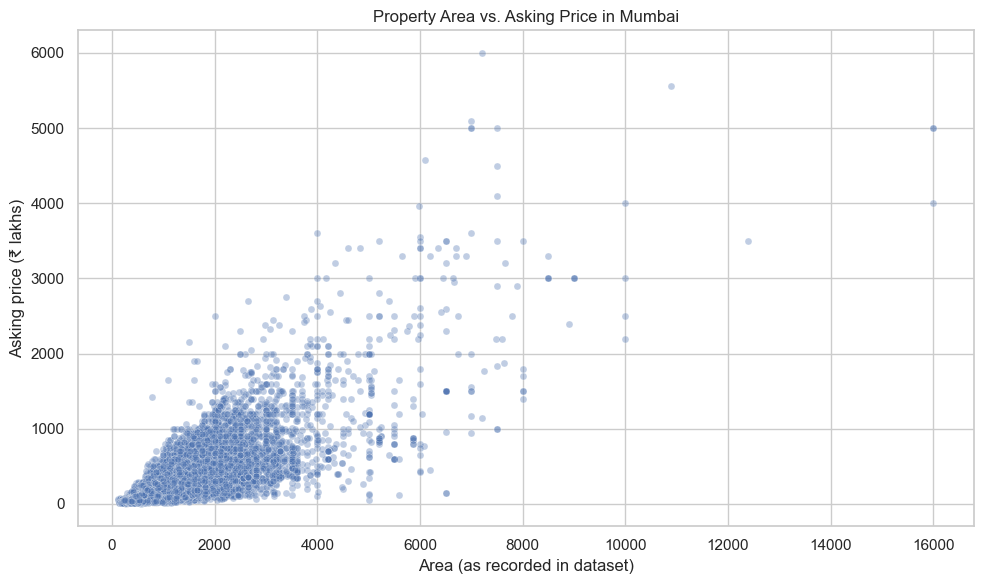

In [35]:
fig, ax = plt.subplots(figsize=(10, 6))

sns.scatterplot(
    data=df_unique,
    x="area",
    y="final_price",
    alpha=0.35,
    s=25,
    ax=ax
)

ax.set_title("Property Area vs. Asking Price in Mumbai")
ax.set_xlabel("Area (as recorded in dataset)")
ax.set_ylabel("Asking price (₹ lakhs)")

plt.tight_layout()
plt.show()

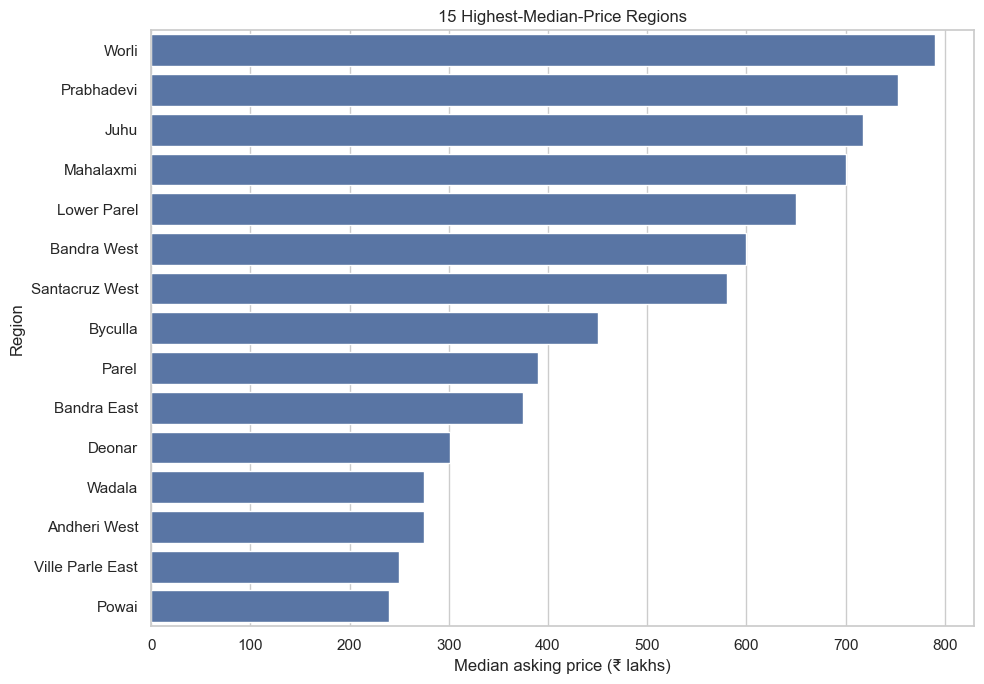

In [36]:
# Keep regions with at least 100 listings
region_counts = df_unique["region"].value_counts()

eligible_regions = region_counts[region_counts >= 100].index

region_medians = (
    df_unique[df_unique["region"].isin(eligible_regions)]
    .groupby("region")["final_price"]
    .median()
    .sort_values(ascending=False)
    .head(15)
)

# Create the chart
fig, ax = plt.subplots(figsize=(10, 7))

sns.barplot(
    x=region_medians.values,
    y=region_medians.index,
    ax=ax
)

ax.set_title("15 Highest-Median-Price Regions")
ax.set_xlabel("Median asking price (₹ lakhs)")
ax.set_ylabel("Region")

plt.tight_layout()
plt.show()

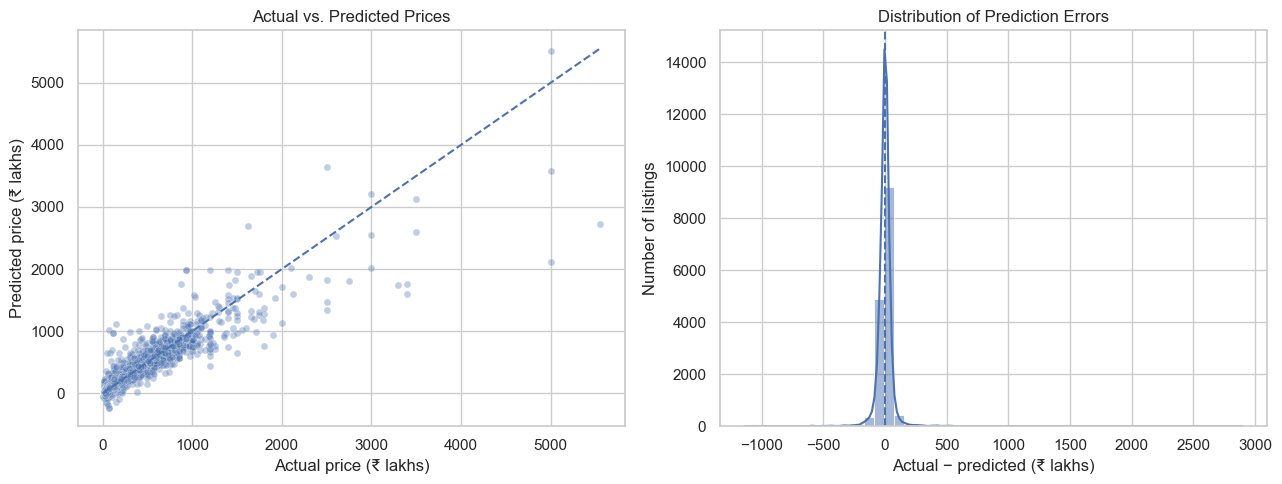

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Actual prices versus predicted prices
sns.scatterplot(
    x=y_test,
    y=y_pred,
    alpha=0.35,
    s=25,
    ax=axes[0]
)

# Reference line: perfect predictions
max_price = max(y_test.max(), y_pred.max())
axes[0].plot(
    [0, max_price],
    [0, max_price],
    linestyle="--"
)

axes[0].set_title("Actual vs. Predicted Prices")
axes[0].set_xlabel("Actual price (₹ lakhs)")
axes[0].set_ylabel("Predicted price (₹ lakhs)")

# Prediction error distribution
residuals = y_test.reset_index(drop=True) - y_pred

sns.histplot(
    residuals,
    bins=50,
    kde=True,
    ax=axes[1]
)

axes[1].axvline(0, linestyle="--")
axes[1].set_title("Distribution of Prediction Errors")
axes[1].set_xlabel("Actual − predicted (₹ lakhs)")
axes[1].set_ylabel("Number of listings")

plt.tight_layout()
plt.show()

In [38]:
from sklearn.model_selection import train_test_split

# Keep one copy of each exact record
df_unique = df.drop_duplicates().copy()

# Separate features and target
feature_columns = [
    "bhk", "type", "locality", "area", "region", "status", "age"
]

X_clean = df_unique[feature_columns]
y_clean = df_unique["final_price"]

# Create a fresh 80/20 split
X_train_clean, X_test_clean, y_train_clean, y_test_clean = train_test_split(
    X_clean,
    y_clean,
    test_size=0.2,
    random_state=42
)

print("Deduplicated dataset:", df_unique.shape)
print("Training rows:", len(X_train_clean))
print("Testing rows:", len(X_test_clean))

Deduplicated dataset: (55726, 10)
Training rows: 44580
Testing rows: 11146


In [39]:
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.dummy import DummyRegressor
import numpy as np

# Reuse the existing preprocessing and model pipeline
clean_model = clone(model)
clean_model.fit(X_train_clean, y_train_clean)

# Make predictions on the new test set
y_pred_clean = clean_model.predict(X_test_clean)

# Evaluate the predictions
clean_mae = mean_absolute_error(y_test_clean, y_pred_clean)
clean_rmse = np.sqrt(mean_squared_error(y_test_clean, y_pred_clean))

print(f"Deduplicated Linear Regression MAE: ₹{clean_mae:.2f} lakhs")
print(f"Deduplicated Linear Regression RMSE: ₹{clean_rmse:.2f} lakhs")

Deduplicated Linear Regression MAE: ₹40.95 lakhs
Deduplicated Linear Regression RMSE: ₹91.23 lakhs


In [40]:
baseline_clean = DummyRegressor(strategy="median")
baseline_clean.fit(X_train_clean, y_train_clean)

baseline_pred_clean = baseline_clean.predict(X_test_clean)

baseline_mae_clean = mean_absolute_error(
    y_test_clean,
    baseline_pred_clean
)

print(f"Median baseline MAE: ₹{baseline_mae_clean:.2f} lakhs")
print(f"Linear Regression MAE: ₹{clean_mae:.2f} lakhs")

improvement = (
    (baseline_mae_clean - clean_mae) / baseline_mae_clean
) * 100

print(f"MAE improvement over baseline: {improvement:.1f}%")

Median baseline MAE: ₹102.44 lakhs
Linear Regression MAE: ₹40.95 lakhs
MAE improvement over baseline: 60.0%


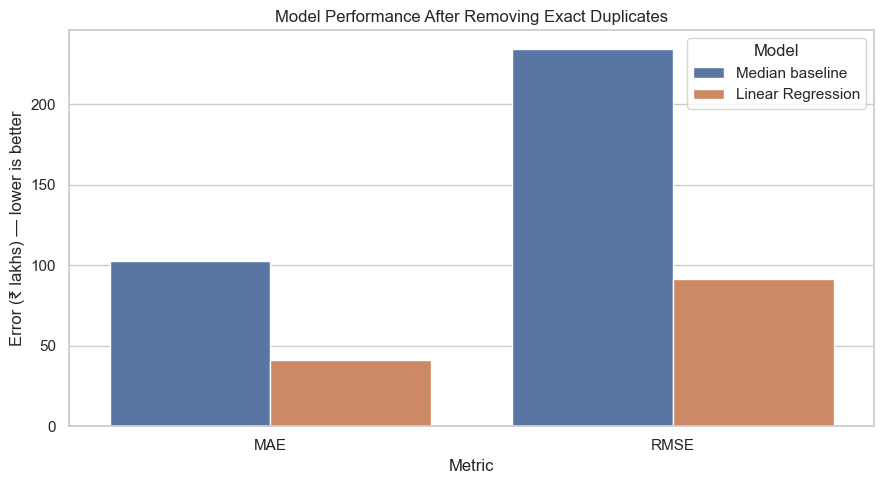

,Metric,Median baseline,Linear Regression
0,MAE,102.439535,40.948563
1,RMSE,234.102928,91.227932


In [41]:
# Compare MAE and RMSE for the deduplicated evaluation
comparison = pd.DataFrame({
    "Metric": ["MAE", "RMSE"],
    "Median baseline": [
        baseline_mae_clean,
        np.sqrt(mean_squared_error(
            y_test_clean, baseline_pred_clean
        ))
    ],
    "Linear Regression": [
        clean_mae,
        clean_rmse
    ]
})

comparison_plot = comparison.melt(
    id_vars="Metric",
    var_name="Model",
    value_name="Error (₹ lakhs)"
)

fig, ax = plt.subplots(figsize=(9, 5))

sns.barplot(
    data=comparison_plot,
    x="Metric",
    y="Error (₹ lakhs)",
    hue="Model",
    ax=ax
)

ax.set_title("Model Performance After Removing Exact Duplicates")
ax.set_ylabel("Error (₹ lakhs) — lower is better")

plt.tight_layout()
plt.show()

display(comparison)

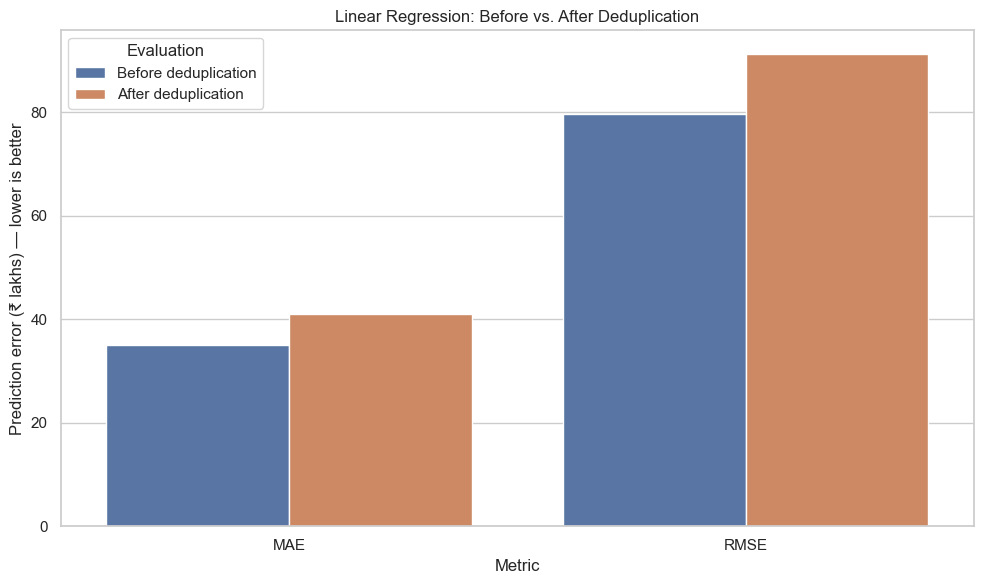

,Evaluation,MAE,RMSE
0,Before deduplication,35.070000,79.650000
1,After deduplication,40.948563,91.227932


In [42]:
# Record the results from both evaluations
before_after = pd.DataFrame({
    "Evaluation": [
        "Before deduplication",
        "After deduplication"
    ],
    "MAE": [35.07, clean_mae],
    "RMSE": [79.65, clean_rmse]
})

# Convert to long format for plotting
comparison_long = before_after.melt(
    id_vars="Evaluation",
    var_name="Metric",
    value_name="Error (₹ lakhs)"
)

fig, ax = plt.subplots(figsize=(10, 6))

sns.barplot(
    data=comparison_long,
    x="Metric",
    y="Error (₹ lakhs)",
    hue="Evaluation",
    ax=ax
)

ax.set_title("Linear Regression: Before vs. After Deduplication")
ax.set_ylabel("Prediction error (₹ lakhs) — lower is better")

plt.tight_layout()
plt.show()

display(before_after)

In [43]:
from sklearn.model_selection import GroupShuffleSplit

# Treat identical feature combinations as a group
groups = df_unique[feature_columns].astype(str).agg("|".join, axis=1)

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(df_unique[feature_columns], df_unique["final_price"], groups=groups)
)

X_train_fair = df_unique[feature_columns].iloc[train_idx]
X_test_fair = df_unique[feature_columns].iloc[test_idx]

y_train_fair = df_unique["final_price"].iloc[train_idx]
y_test_fair = df_unique["final_price"].iloc[test_idx]

print("Training rows:", len(X_train_fair))
print("Testing rows:", len(X_test_fair))
print(
    "Feature combinations shared between sets:",
    len(
        set(groups.iloc[train_idx])
        & set(groups.iloc[test_idx])
    )
)

Training rows: 44571
Testing rows: 11155
Feature combinations shared between sets: 0


In [44]:
from sklearn.base import clone
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Train Linear Regression on the stricter split
linear_fair = clone(model)
linear_fair.fit(X_train_fair, y_train_fair)

linear_pred_fair = linear_fair.predict(X_test_fair)

# Build Ridge Regression using the same preprocessing
ridge_fair = Pipeline([
    ("preprocessor", clone(model.named_steps["preprocessor"])),
    ("regressor", Ridge(alpha=10.0))
])

ridge_fair.fit(X_train_fair, y_train_fair)
ridge_pred_fair = ridge_fair.predict(X_test_fair)

print("Both models trained on the same split.")

Both models trained on the same split.


In [45]:
def evaluate_regression(y_true, y_pred, model_name):
    return {
        "Model": model_name,
        "MAE (₹ lakhs)": mean_absolute_error(y_true, y_pred),
        "RMSE (₹ lakhs)": np.sqrt(
            mean_squared_error(y_true, y_pred)
        )
    }

fair_results = pd.DataFrame([
    evaluate_regression(
        y_test_fair, linear_pred_fair, "Linear Regression"
    ),
    evaluate_regression(
        y_test_fair, ridge_pred_fair, "Ridge Regression"
    )
])

display(fair_results.round(2))

,Model,MAE (₹ lakhs),RMSE (₹ lakhs)
0,Linear Regression,41.12,93.81
1,Ridge Regression,74.12,131.60


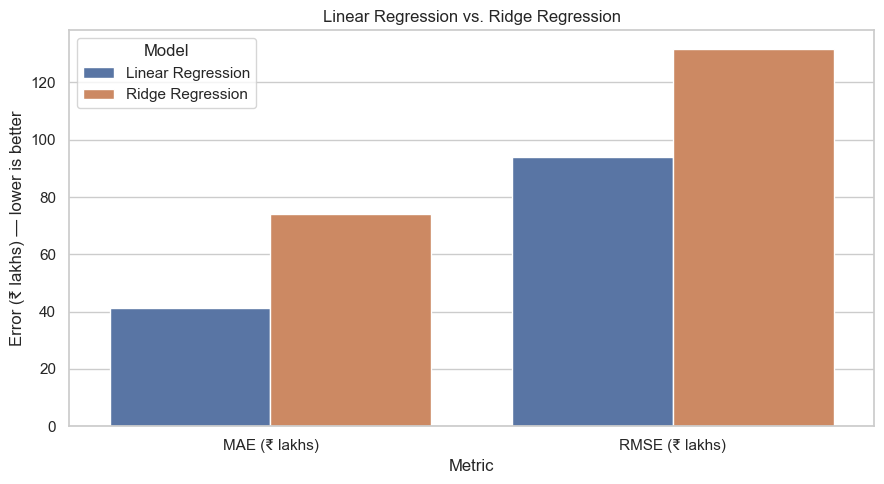

In [46]:
results_long = fair_results.melt(
    id_vars="Model",
    var_name="Metric",
    value_name="Error (₹ lakhs)"
)

fig, ax = plt.subplots(figsize=(9, 5))

sns.barplot(
    data=results_long,
    x="Metric",
    y="Error (₹ lakhs)",
    hue="Model",
    ax=ax
)

ax.set_title("Linear Regression vs. Ridge Regression")
ax.set_ylabel("Error (₹ lakhs) — lower is better")

plt.tight_layout()
plt.show()

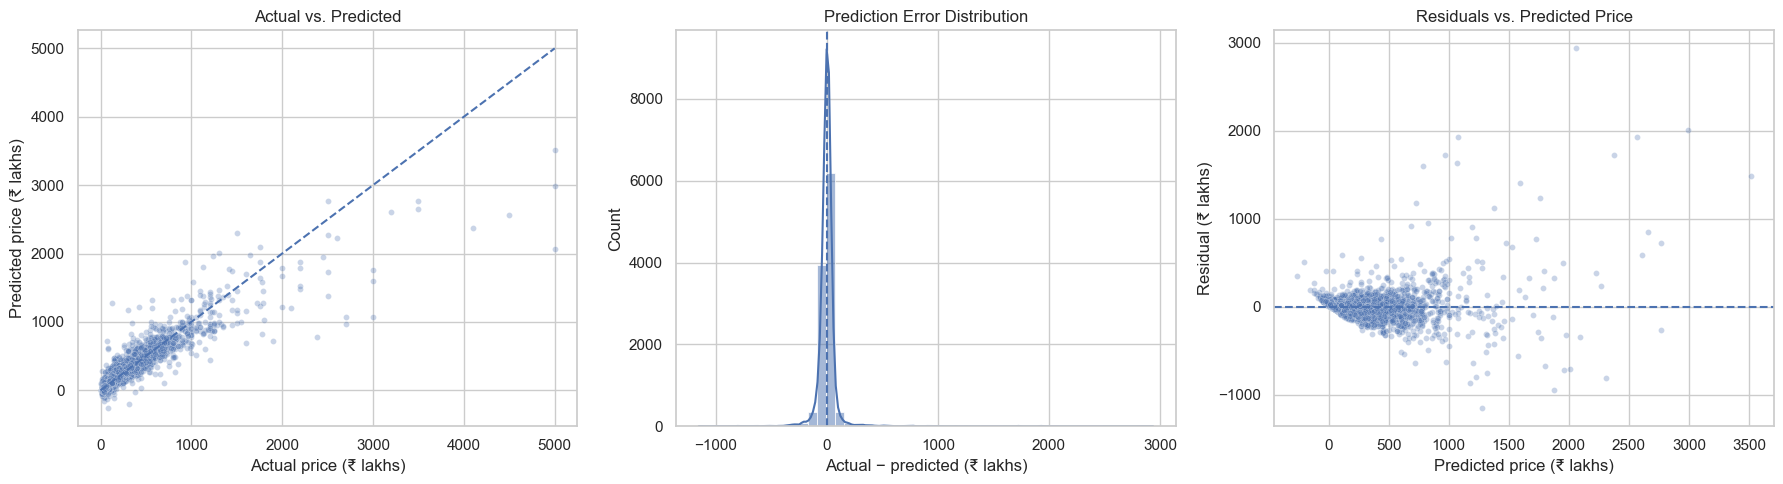

In [47]:
# Calculate prediction errors on the strict test set
actual = y_test_fair.to_numpy()
predicted = linear_pred_fair
residuals = actual - predicted

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Actual vs. predicted prices
sns.scatterplot(
    x=actual, y=predicted,
    alpha=0.3, s=18, ax=axes[0]
)

limit = max(actual.max(), predicted.max())
axes[0].plot([0, limit], [0, limit], "--")
axes[0].set_title("Actual vs. Predicted")
axes[0].set_xlabel("Actual price (₹ lakhs)")
axes[0].set_ylabel("Predicted price (₹ lakhs)")

# 2. Distribution of residuals
sns.histplot(
    residuals, bins=50, kde=True, ax=axes[1]
)
axes[1].axvline(0, linestyle="--")
axes[1].set_title("Prediction Error Distribution")
axes[1].set_xlabel("Actual − predicted (₹ lakhs)")

# 3. Residuals vs. predicted prices
sns.scatterplot(
    x=predicted, y=residuals,
    alpha=0.3, s=18, ax=axes[2]
)
axes[2].axhline(0, linestyle="--")
axes[2].set_title("Residuals vs. Predicted Price")
axes[2].set_xlabel("Predicted price (₹ lakhs)")
axes[2].set_ylabel("Residual (₹ lakhs)")

plt.tight_layout()
plt.show()

In [48]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Baseline: predict the median training price for every property
dummy_model = DummyRegressor(strategy="median")
dummy_model.fit(X_train_fair, y_train_fair)

dummy_pred_fair = dummy_model.predict(X_test_fair)

# Evaluate all three models on the exact same test set
final_results = pd.DataFrame([
    {
        "Model": "Median Baseline",
        "MAE (₹ lakhs)": mean_absolute_error(y_test_fair, dummy_pred_fair),
        "RMSE (₹ lakhs)": np.sqrt(mean_squared_error(y_test_fair, dummy_pred_fair))
    },
    {
        "Model": "Linear Regression",
        "MAE (₹ lakhs)": mean_absolute_error(y_test_fair, linear_pred_fair),
        "RMSE (₹ lakhs)": np.sqrt(mean_squared_error(y_test_fair, linear_pred_fair))
    },
    {
        "Model": "Ridge Regression",
        "MAE (₹ lakhs)": mean_absolute_error(y_test_fair, ridge_pred_fair),
        "RMSE (₹ lakhs)": np.sqrt(mean_squared_error(y_test_fair, ridge_pred_fair))
    }
])

display(final_results.round(2))

,Model,MAE (₹ lakhs),RMSE (₹ lakhs)
0,Median Baseline,103.79,240.31
1,Linear Regression,41.12,93.81
2,Ridge Regression,74.12,131.60


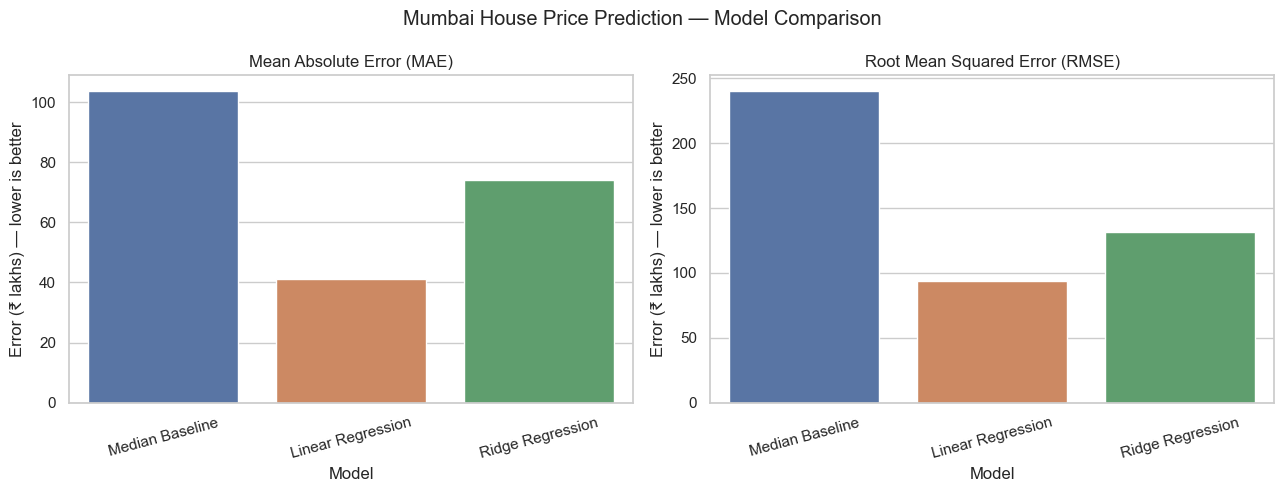

In [49]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Compare MAE
sns.barplot(
    data=final_results,
    x="Model",
    y="MAE (₹ lakhs)",
    hue="Model",
    legend=False,
    ax=axes[0]
)
axes[0].set_title("Mean Absolute Error (MAE)")
axes[0].set_ylabel("Error (₹ lakhs) — lower is better")
axes[0].tick_params(axis="x", rotation=15)

# Compare RMSE
sns.barplot(
    data=final_results,
    x="Model",
    y="RMSE (₹ lakhs)",
    hue="Model",
    legend=False,
    ax=axes[1]
)
axes[1].set_title("Root Mean Squared Error (RMSE)")
axes[1].set_ylabel("Error (₹ lakhs) — lower is better")
axes[1].tick_params(axis="x", rotation=15)

plt.suptitle("Mumbai House Price Prediction — Model Comparison")
plt.tight_layout()
plt.show()

In [54]:
# Three sample properties for testing
sample_properties = pd.DataFrame([
    {
        "bhk": 1,
        "type": "Apartment",
        "locality": "Powai",
        "area": 500,
        "region": "Powai",
        "status": "Ready to move",
        "age": "Resale"
    },
    {
        "bhk": 2,
        "type": "Apartment",
        "locality": "Andheri",
        "area": 900,
        "region": "Andheri West",
        "status": "Ready to move",
        "age": "Resale"
    },
    {
        "bhk": 3,
        "type": "Apartment",
        "locality": "Worli",
        "area": 1500,
        "region": "Worli",
        "status": "Under Construction",
        "age": "New"
    }
])

# Predict asking prices using our best model
sample_predictions = linear_fair.predict(sample_properties)

# Display results in a readable table
sample_results = sample_properties.copy()
sample_results["Predicted Price (₹ lakhs)"] = sample_predictions
sample_results["Predicted Price (₹ crore)"] = sample_predictions / 100

display(sample_results.round(2))

,bhk,type,locality,area,region,status,age,Predicted Price (₹ lakhs),Predicted Price (₹ crore)
0,1,Apartment,Powai,500,Powai,Ready to move,Resale,175.05,1.75
1,2,Apartment,Andheri,900,Andheri West,Ready to move,Resale,273.42,2.73
2,3,Apartment,Worli,1500,Worli,Under Construction,New,926.71,9.27


In [55]:
for col in ["locality", "region"]:
    known_values = set(X_train_fair[col].dropna().unique())

    print(f"\n{col.upper()}")
    for value in sample_properties[col]:
        print(f"{value}: {'Known' if value in known_values else 'UNSEEN'}")


LOCALITY
Powai: UNSEEN
Andheri: UNSEEN
Worli: UNSEEN

REGION
Powai: Known
Andheri West: Known
Worli: Known


In [56]:
# Select actual localities from the training data
known_localities = X_train_fair["locality"].dropna().unique()

print("Sample known localities:")
print(known_localities[:20])

Sample known localities:
['Lak And Hanware The Residency Tower' 'Romell Serene' 'Origin Oriana'
 'Bhoomi Simana Wing A Phase 1' 'Agami Estancia' 'Sanghvi Infenia'
 'Shubh Shreeji Heights' 'Aplite Greenstone Heritage'
 'A Plus Golden Corner' 'Unimont Imperia' 'Roswalt Zaiden'
 'Angel Falcon Emerald Dunlin'
 'Proviso Sai Proviso Icon Greater Kharghar Roadpali' 'Godrej Urban Park'
 'Aurum Q Island R4 AND R5' 'Asshna Seabliss' 'Mayfair The View'
 'Vardhan Heights' 'Puraniks Unicorn Phase 1' 'Pyramid Elements']


In [57]:
# Get three distinct property examples from the training data
sample_indices = X_train_fair.index[:]

demo_properties = (
    df_unique.loc[sample_indices, feature_columns]
    .drop_duplicates(subset=["locality", "region"])
    .groupby("region", group_keys=False)
    .head(1)
    .head(3)
    .copy()
)

display(demo_properties)

,bhk,type,locality,area,region,status,age
0,3,Apartment,Lak And Hanware The Residency Tower,685,Andheri West,Ready to move,New
2,2,Apartment,Romell Serene,610,Borivali West,Under Construction,New
4,2,Apartment,Origin Oriana,659,Mira Road East,Under Construction,New


In [58]:
# Predict prices for properties with known locality-region combinations
demo_predictions = linear_fair.predict(demo_properties)

demo_results = demo_properties.copy()
demo_results["Predicted Price (₹ lakhs)"] = demo_predictions
demo_results["Predicted Price (₹ crore)"] = demo_predictions / 100

display(demo_results.round(2))

,bhk,type,locality,area,region,status,age,Predicted Price (₹ lakhs),Predicted Price (₹ crore)
0,3,Apartment,Lak And Hanware The Residency Tower,685,Andheri West,Ready to move,New,195.57,1.96
2,2,Apartment,Romell Serene,610,Borivali West,Under Construction,New,172.74,1.73
4,2,Apartment,Origin Oriana,659,Mira Road East,Under Construction,New,73.32,0.73


In [59]:
# Match the selected properties to their recorded prices
demo_comparison = demo_results.copy()

demo_comparison["Actual Price (₹ lakhs)"] = [
    df_unique.loc[
        (df_unique["locality"] == row["locality"]) &
        (df_unique["region"] == row["region"]) &
        (df_unique["bhk"] == row["bhk"]) &
        (df_unique["area"] == row["area"]),
        "final_price"
    ].iloc[0]
    for _, row in demo_properties.iterrows()
]

demo_comparison["Absolute Error (₹ lakhs)"] = abs(
    demo_comparison["Actual Price (₹ lakhs)"] -
    demo_comparison["Predicted Price (₹ lakhs)"]
)

display(demo_comparison.round(2))

,bhk,type,locality,area,region,status,age,Predicted Price (₹ lakhs),Predicted Price (₹ crore),Actual Price (₹ lakhs),Absolute Error (₹ lakhs)
0,3,Apartment,Lak And Hanware The Residency Tower,685,Andheri West,Ready to move,New,195.57,1.96,250.00,54.43
2,2,Apartment,Romell Serene,610,Borivali West,Under Construction,New,172.74,1.73,173.00,0.26
4,2,Apartment,Origin Oriana,659,Mira Road East,Under Construction,New,73.32,0.73,94.11,20.79


In [60]:
print(
    "Average absolute error on demo properties: ₹",
    round(demo_comparison["Absolute Error (₹ lakhs)"].mean(), 2),
    "lakhs"
)

Average absolute error on demo properties: ₹ 25.16 lakhs


## Final Model Evaluation

Three regression approaches were evaluated on the same strict test set, with feature combinations separated between training and testing.

| Model | MAE (₹ lakhs) | RMSE (₹ lakhs) |
|---|---:|---:|
| Median Baseline | 103.79 | 240.31 |
| Linear Regression | 41.12 | 93.81 |
| Ridge Regression | 74.12 | 131.60 |

Linear Regression achieved the lowest MAE and RMSE among the three evaluated models. Its MAE was approximately 60.4% lower than the median baseline.

### Key Findings
- Property asking prices show substantial variation across localities and property characteristics.
- The model performs better for many lower- and mid-priced properties than for some high-priced properties.
- Residual analysis indicates that large prediction errors remain, particularly for expensive properties.
- Exact duplicate rows were removed before the stricter evaluation.
- Ridge Regression with `alpha=10.0` performed worse than Linear Regression in this evaluation; other regularization settings were not tested.

### Limitations
- The dataset contains asking prices, not verified property transaction prices.
- The original dataset's provenance and area measurement unit require further verification.
- The evaluation uses a random group-based split, not a time-based split; results may differ on future listings.
- Predictions are estimates and should not be treated as property valuations.

### Conclusion
Linear Regression is the best-performing model among the three approaches tested on this evaluation split. Further improvements could include tuning regularization, engineering location-based features, and evaluating additional regression models.